# LightGBM against Chronos-2

**What this notebook does:** fits LightGBM, a model trained only on Irish data, and scores it in the same day-by-day test as Chronos-2 (notebooks 01 and 02), on the same half-hours. Until now Chronos-2 had only beaten simple methods; this is the first proper competitor.

**Before running:** `pip install -e ".[foundation,gbm,notebooks]"`, with isem-data next to this project. The wind test takes a few minutes; the year test at the end takes longer (see the note there).

## LightGBM, in plain words

- **A decision tree** is a set of yes/no questions ending in an answer: "is it between 17:00 and 19:00? Is the wind forecast below 1,500 MW? Then about €40 above yesterday's average." It is learned from examples by choosing, at each step, the question that best splits them.
- **Gradient boosting** builds hundreds of small trees one after another. Each new tree is fitted to what the trees before it still get wrong, and the forecast is the sum of them all. Each tree is weak; together they're strong. LightGBM is a fast version of this, and gradient-boosted trees are what most forecasting competitions on tables of data are won with.
- **It learns only from what it's given.** Chronos-2 arrives having seen millions of series; LightGBM starts from nothing and learns from Irish history alone. So it needs the history turned into a table: one row per half-hour, one column per thing known before the auction (the *features*).
- **It is refitted every day** on every day before the one it forecasts, then forecasts that day. It never sees the future.
- **Ranges too.** Besides the central forecast (fitted to the median, like Chronos-2's), two more models are fitted to the 10% and 90% quantiles, so it gives an 80% range that can be checked the same way.

## The features

| Feature | What it is |
|---|---|
| `slot`, `weekday` | the half-hour of the trading day (23:00 is 0), the day of the week |
| `price_1d`, `price_2d`, `price_7d` | the price at the same time 1, 2 and 7 days earlier |
| `yesterday_mean`, `yesterday_min`, `yesterday_max` | the day before's average, lowest and highest price |
| `week_mean` | the average over the 7 days before |
| `wind`, `wind_day_mean`, `wind_yesterday_mean` | EirGrid's wind forecast as it stood before the auction: this half-hour, the whole day, and the day before |

Every price feature comes from an earlier trading day; `tests/test_gbm.py` checks it, including on clock-change days, where 24 hours earlier can still be the same trading day.

**It forecasts the change from yesterday's average**, then adds the average back. Trees can only answer with values like those they were trained on, and prices roughly doubled over the year; the change from yesterday stays in a familiar range.

**Its settings were fixed before testing** (400 trees of 15 leaves, a slow learning rate, 80% of rows and columns for each tree) and not tuned on the results; see `PARAMS` in `gbm.py`. Tuning on the test days would flatter it.

In [1]:
import warnings
from datetime import timedelta

import matplotlib.pyplot as plt
import pandas as pd

from isem_forecast.baselines import BASELINES
from isem_forecast.data import delivery_day, load_prices, wind_forecast_before_auction
from isem_forecast.evaluate import errors, mae_by_month, summary, walk_forward
from isem_forecast.foundation import Chronos2, load_model, share_inside
from isem_forecast.gbm import LightGBM, build_features

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 1)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})

prices = load_prices()
wind = wind_forecast_before_auction()["forecast_mw"]
last = max(delivery_day(prices.index))

# The features for the last day: what LightGBM is given to forecast it.
targets = prices.index[delivery_day(prices.index) == last]
build_features(prices[prices.index < targets[0]], targets, wind).head(4).T

timestamp_utc,2026-11-16 23:00:00+00:00,2026-11-16 23:30:00+00:00,2026-11-17 00:00:00+00:00,2026-11-17 00:30:00+00:00
slot,0.0,1.0,2.0,3.0
weekday,1.0,1.0,1.0,1.0
price_1d,275.0,269.2,279.4,271.7
price_2d,203.5,200.6,207.5,208.9
price_7d,236.6,229.3,224.5,221.4
yesterday_mean,282.2,282.2,282.2,282.2
yesterday_min,191.0,191.0,191.0,191.0
yesterday_max,521.3,521.3,521.3,521.3
week_mean,291.3,291.3,291.3,291.3
wind,3818.8,3693.3,3570.7,3456.3


## The test with wind

The same days as notebook 02: from a month after the first wind forecast kept, to the latest prices. LightGBM with wind trains only on half-hours that have the forecast, so it starts with a month of rows (about 1,300) and gains 48 a day.

In [2]:
model = (
    load_model()
)  # Chronos-2; load_model() also loads LightGBM's OpenMP first (see foundation.py)
start = min(delivery_day(wind.index)) + timedelta(days=28)

methods = {
    "week_average": BASELINES["week_average"],
    "chronos2": Chronos2(model, 28),
    "chronos2_wind": Chronos2(model, 28, {"wind": wind}),
    "lightgbm": LightGBM(None),
    "lightgbm_wind": LightGBM(wind),
}
results = {name: walk_forward(prices, method, start, last) for name, method in methods.items()}

common = errors(results).index
print(
    f"Delivery days {start} to {last}: {len(set(delivery_day(common)))} days, "
    f"{len(common):,} half-hours, the same for every method"
)


def with_ranges(results, methods):
    table = summary(results)
    table["inside 80% range"] = [
        f"{share_inside(methods[m].ranges().reindex(common), prices):.0%}"
        if hasattr(methods[m], "ranges")
        else ""
        for m in table.index
    ]
    return table


with_ranges(results, methods)

W1118 11:53:16.628000 79218 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Delivery days 2026-09-09 to 2026-11-17: 70 days, 3,362 half-hours, the same for every method


,MAE,RMSE,inside 80% range
chronos2_wind,36.3,52.9,73%
lightgbm_wind,46.6,64.6,47%
chronos2,47.3,67.9,70%
lightgbm,65.6,87.0,52%
week_average,66.3,87.3,


In [3]:
mae_by_month(results)

,week_average,chronos2,chronos2_wind,lightgbm,lightgbm_wind
2026-09,47.1,37.9,28.1,45.8,36.4
2026-10,63.8,44.4,32.8,60.5,42.8
2026-11,95.6,64.7,53.3,100.6,66.7


## Two checks on LightGBM's set-up

Two choices above could have gone the other way. Each is tried here on the same days, as a check on the choice, not to pick the better score:

- `all_days`: train on every day since November 2025, with the wind features missing before August (LightGBM handles missing values), so it has ten times as many rows.
- `raw_price`: forecast the price itself rather than the change from yesterday's average.

In [4]:
checks = {
    "lightgbm_wind_all_days": LightGBM(wind, wind_only=False),
    "lightgbm_wind_raw_price": LightGBM(wind, target="price"),
}
check_results = {"lightgbm_wind": results["lightgbm_wind"]}
for name, method in checks.items():
    check_results[name] = walk_forward(prices, method, start, last)
summary(check_results)

,MAE,RMSE
lightgbm_wind_raw_price,43.9,60.2
lightgbm_wind,46.6,64.6
lightgbm_wind_all_days,49.9,69.1


## What LightGBM leans on

*Gain* adds up how much each feature's questions improved the fit, across all the trees of the last day's median model. Bigger means it leaned on it more.

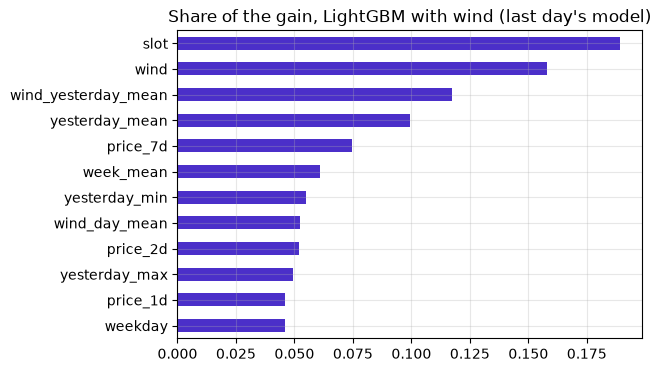

In [5]:
latest = methods["lightgbm_wind"].last_models["median"]
gain = pd.Series(latest.booster_.feature_importance("gain"), index=latest.feature_name_)
(gain / gain.sum()).sort_values().plot.barh(color="#4b2fc9", figsize=(6, 4))
plt.title("Share of the gain, LightGBM with wind (last day's model)")
plt.show()

## Side by side on three days

The days where the two models with wind differ most, and the latest day.

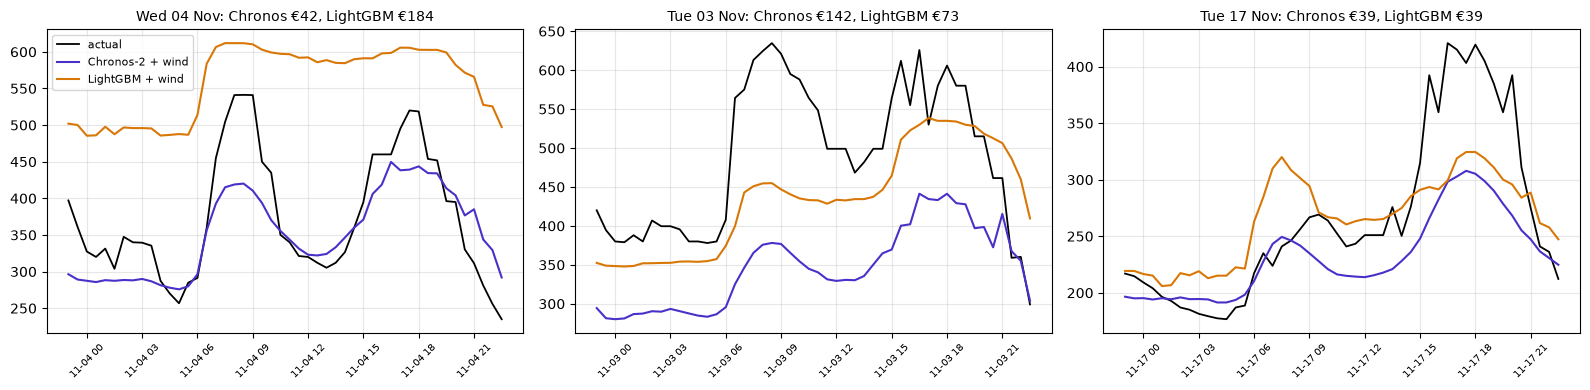

In [6]:
miss = errors(results).abs().groupby(delivery_day(common)).mean()
gap = miss["lightgbm_wind"] - miss["chronos2_wind"]
chosen = [gap.idxmax(), gap.idxmin(), max(miss.index)]

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=False)
for day, ax in zip(chosen, axes, strict=True):
    t = common[delivery_day(common) == day]
    local = t.tz_convert("Europe/Dublin")
    ax.plot(local, prices[t], color="black", lw=1.3, label="actual")
    ax.plot(
        local,
        results["chronos2_wind"]["forecast"].reindex(t),
        color="#4b2fc9",
        label="Chronos-2 + wind",
    )
    ax.plot(
        local,
        results["lightgbm_wind"]["forecast"].reindex(t),
        color="#d97706",
        label="LightGBM + wind",
    )
    ax.set_title(
        f"{day:%a %d %b}: Chronos €{miss.loc[day, 'chronos2_wind']:.0f}, "
        f"LightGBM €{miss.loc[day, 'lightgbm_wind']:.0f}",
        fontsize=10,
    )
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## A year, prices only

Without wind, both models can be tested over the whole year, as in notebook 01. LightGBM starts after a month, once it has 28 days to learn from, so the first month is left out for every method.

**This is slow:** LightGBM is refitted 360 times, on up to 17,000 rows, three models each time. It takes about 8 minutes on an M1 Pro. Set `RUN_YEAR = False` to skip it.

In [7]:
RUN_YEAR = True

if RUN_YEAR:
    year_methods = {
        "week_average": BASELINES["week_average"],
        "chronos2": Chronos2(model, 28),
        "lightgbm": LightGBM(None),
    }
    first = min(delivery_day(prices.index)) + timedelta(days=7)
    year = {name: walk_forward(prices, m, first, last) for name, m in year_methods.items()}
    year_common = errors(year).index
    print(
        f"Delivery days {min(delivery_day(year_common))} to {last}: "
        f"{len(year_common):,} half-hours, the same for every method"
    )
    common = year_common  # with_ranges() scores the ranges on these half-hours
    display(with_ranges(year, year_methods))
    display(mae_by_month(year))

Delivery days 2025-12-06 to 2026-11-17: 16,656 half-hours, the same for every method


,MAE,RMSE,inside 80% range
chronos2,28.5,43.7,73%
week_average,37.6,54.1,
lightgbm,38.0,54.8,57%


,week_average,chronos2,lightgbm
2025-12,30.1,21.2,36.0
2026-01,24.0,21.5,23.7
2026-02,25.1,18.5,23.3
2026-03,45.5,31.9,40.1
2026-04,43.2,31.7,43.8
2026-05,22.5,18.4,26.8
2026-06,33.3,26.7,32.1
2026-07,28.7,24.0,30.2
2026-08,19.8,17.0,21.4
2026-09,43.1,36.8,44.8


## What this shows

From the run on 18 Nov 2026, with prices to 17 Nov:

**With the wind forecast (9 Sep to 17 Nov 2026, 70 days):**

| Method | MAE (€/MWh) | Inside 80% range |
|---|---|---|
| Chronos-2 + wind | **36.3** | 73% |
| LightGBM + wind | 46.6 | 47% |
| Chronos-2, prices only | 47.3 | 70% |
| LightGBM, prices only | 65.6 | 52% |
| `week_average` | 66.3 | |

**A year on prices alone (6 Dec 2025 to 17 Nov 2026):** Chronos-2 €28.5, `week_average` €37.6, LightGBM €38.0. Chronos-2 was ahead of LightGBM in every month.

- **Chronos-2 wins clearly, with and without wind.** With the same inputs, it missed by about €10/MWh less than LightGBM: about a fifth.
- **Wind helps both models by about the same amount** (€11/MWh for Chronos-2, €19 for LightGBM). LightGBM leans on it hard: without it, it's no better than the 7-day average.
- **LightGBM is short of data.** With wind it starts with one month of rows, and on prices alone a year of half-hours is still small for trees. Chronos-2 brings what it learned elsewhere; LightGBM has only Irish data. This is the main argument for pre-trained models, and it's strongest when data is short.
- **LightGBM's ranges are much too narrow.** Only 47% of prices landed in its 80% range: its 10% and 90% models are too sure of themselves on so little data. Chronos-2's ranges are a little too narrow too (73%), but far closer.
- **The checks:** forecasting the price itself, rather than the change from yesterday, scored €43.9, better than the set-up chosen in advance, but still well behind Chronos-2. Training on every day, with wind missing before August, scored €49.9, worse.

Read with care: this is one LightGBM set-up, chosen in advance and not tuned. A carefully built model (more features, tuned settings, a demand forecast) would do better, and Chronos-2's margin could shrink. 70 days, mostly a stormy autumn.


## Next

- **LEAR**, the other standard competitor in the literature: a linear model on the prices of each hour of the past days, with automatic selection of which ones matter (LASSO). Different from trees, and often strong on electricity prices.
- **Chronos-2 and LightGBM together:** averaging the two often beats both, when their mistakes differ.
- **More known-future inputs** for both: EirGrid's demand forecast, kept version by version like the wind forecast.